# Urban land cover fractions from EnMAP: Potsdam

How much of each 30 m EnMAP pixel is vegetation, sealed surface, soil or water? This notebook
estimates these **fractions** with regression-based unmixing and synthetically mixed training data
(following Okujeni et al. 2013), validates them against a 1 m reference, and asks whether the
hyperspectral data does better than (simulated) Sentinel-2.

**Data** (EnMAP-Box example data, not included in this repository):

| File | Content |
|---|---|
| `enmap_potsdam.tif` | EnMAP L2A surface reflectance, Potsdam, 24 July 2022, 224 bands, 30 m |
| `landcover_potsdam_polygon.gpkg` | Land cover polygons derived from a 1 m aerial image (April 2019) |

**Steps**

1. Band quality check and band selection
2. Reference fractions per EnMAP pixel from the 1 m polygons
3. Spectral library of pure pixels
4. Synthetic mixing and Random Forest regression
5. Comparison with simulated Sentinel-2
6. Final test and fraction maps

EnMAP data © DLR 2022. Results are value added products: *Contains modified EnMAP data © DLR 2022.*

## Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import rioxarray
import xarray as xr
import geopandas as gpd
from rasterio.features import rasterize
from rasterio.transform import Affine
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

# Find the project folder: go up from here until we find environment.yml
PROJECT = Path.cwd()
while not (PROJECT / "environment.yml").exists():
    if PROJECT == PROJECT.parent:
        raise FileNotFoundError("No environment.yml found in any parent folder")
    PROJECT = PROJECT.parent

DATA = PROJECT / "data"
OUTPUTS = PROJECT / "outputs"
OUTPUTS.mkdir(exist_ok=True)

SEED = 42
CLASSES = ["impervious", "vegetation", "soil", "water"]
COLORS = {"impervious": "tab:grey", "vegetation": "tab:green", "soil": "tab:brown", "water": "tab:blue"}

print("Project:", PROJECT.name)
print("Data folder exists:", DATA.exists())

Project: enmap
Data folder exists: True


In [2]:
def plot_with_gaps(ax, x, y, **kwargs):
    # Plot a spectrum and leave gaps where bands were removed (> 30 nm apart)
    breaks = np.where(np.diff(x) > 30)[0] + 1
    ax.plot(np.insert(np.asarray(x, dtype=float), breaks, np.nan),
            np.insert(np.asarray(y, dtype=float), breaks, np.nan), **kwargs)

## 1. EnMAP image and band quality

Reflectance is stored × 10,000 with -32768 as no-data. Each band carries its wavelength, width (FWHM)
and a bad band flag (`bbl`).

In [3]:
enmap = rioxarray.open_rasterio(DATA / "enmap_potsdam.tif")
n_rows, n_cols = enmap.rio.height, enmap.rio.width

print("Shape (bands, rows, columns):", enmap.shape)
print("CRS:", enmap.rio.crs, "| pixel size:", enmap.rio.resolution())

rows = []
with rasterio.open(DATA / "enmap_potsdam.tif") as src:
    for b in range(1, src.count + 1):
        tags = src.tags(b)
        rows.append({
            "band": b,
            "wavelength_nm": float(tags["wavelength"]),
            "fwhm_nm": float(tags["fwhm"]),
            "good": tags["bbl"] == "1",
        })
bands = pd.DataFrame(rows)

# EnMAP has two detectors; the SWIR bands start where the wavelength jumps back down
jump = np.where(np.diff(bands["wavelength_nm"]) < 0)[0][0] + 1
bands["detector"] = np.where(bands.index < jump, "VNIR", "SWIR")
print(bands.groupby("detector")["wavelength_nm"].agg(["count", "min", "max"]))
print("Bands flagged bad in the file:", (~bands["good"]).sum())

Shape (bands, rows, columns): (224, 200, 330)
CRS: EPSG:32633 | pixel size: (30.0, -30.0)
          count      min       max
detector                          
SWIR        133  902.257  2445.530
VNIR         91  418.240   993.083
Bands flagged bad in the file: 6


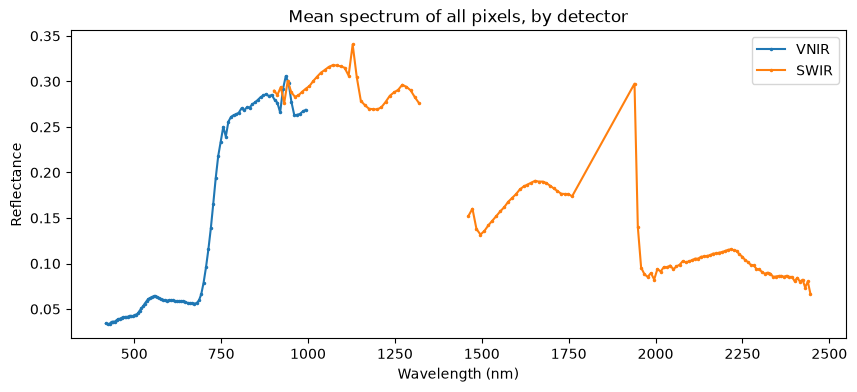

In [4]:
data = enmap.values.astype("float32")
data[data == enmap.rio.nodata] = np.nan
refl = data / 10000

# The bad bands contain only no-data, so their mean is NaN (warning suppressed)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    mean_spectrum = np.nanmean(refl, axis=(1, 2))

fig, ax = plt.subplots(figsize=(10, 4))
for det, color in [("VNIR", "tab:blue"), ("SWIR", "tab:orange")]:
    sel = (bands["detector"] == det).values
    ax.plot(bands.loc[sel, "wavelength_nm"], mean_spectrum[sel], marker=".", markersize=3, color=color, label=det)
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Reflectance")
ax.set_title("Mean spectrum of all pixels, by detector")
ax.legend()
plt.show()

### Band selection

The file flags only 6 bands as bad (1330 to 1390 nm). The mean spectrum shows more problems:
spikes at oxygen and water vapour absorptions (760, 940, 1130, 1940 nm), an unstable VNIR detector
edge above 900 nm (VNIR and SWIR overlap between 902 and 993 nm) and noise above 2400 nm. These match
the known issues described in the EnMAP validation paper (Brell et al. 2026).

Bands kept: 185 of 224


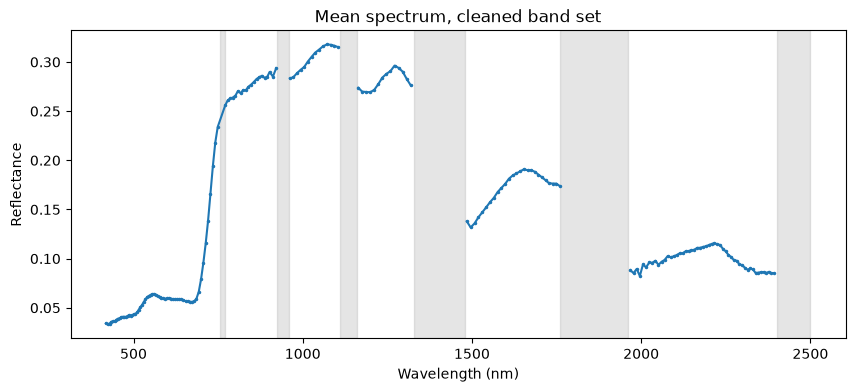

In [5]:
wl = bands["wavelength_nm"]
DROP_RANGES = [(755, 770), (925, 960), (1110, 1160), (1330, 1480), (1760, 1960), (2400, 2500)]

in_drop_range = np.zeros(len(bands), dtype=bool)
for lo, hi in DROP_RANGES:
    in_drop_range |= wl.between(lo, hi)
vnir_edge = (bands["detector"] == "VNIR") & (wl > 900)

bands["use"] = bands["good"] & ~in_drop_range & ~vnir_edge
use = bands["use"].values
wl_use = bands.loc[use, "wavelength_nm"].values
print("Bands kept:", use.sum(), "of", len(bands))

fig, ax = plt.subplots(figsize=(10, 4))
plot_with_gaps(ax, wl_use, mean_spectrum[use], marker=".", markersize=3)
for lo, hi in DROP_RANGES:
    ax.axvspan(lo, hi, color="grey", alpha=0.2)
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Reflectance")
ax.set_title("Mean spectrum, cleaned band set")
plt.show()

bands.to_csv(OUTPUTS / "enmap_band_selection.csv", index=False)

## 2. Reference fractions from the 1 m land cover polygons

The polygons are drawn on a 1 m grid aligned with the EnMAP pixels. Each 30 m pixel contains
30 × 30 cells, and the share of each class gives the reference fraction. Only pixels fully covered
by polygons are used.

In [6]:
lc = gpd.read_file(DATA / "landcover_potsdam_polygon.gpkg", layer="landcover_potsdam_polygon")
print("Polygons:", len(lc), "| CRS:", lc.crs)
lc["area_ha"] = lc.area / 10000
print(lc.groupby("level_1")["area_ha"].sum().round(1))

codes = lc["level_1"].map({c: i + 1 for i, c in enumerate(CLASSES)})
t = enmap.rio.transform()
fine_transform = Affine(1, 0, t.c, 0, -1, t.f)

lc_1m = rasterize(
    zip(lc.geometry, codes),
    out_shape=(n_rows * 30, n_cols * 30),
    transform=fine_transform,
    fill=0,
    dtype="uint8",
)
blocks = lc_1m.reshape(n_rows, 30, n_cols, 30)

coverage = (blocks > 0).mean(axis=(1, 3))
fractions = {c: (blocks == i + 1).mean(axis=(1, 3)) for i, c in enumerate(CLASSES)}
full = coverage == 1
print("EnMAP pixels fully covered by reference:", full.sum())

Polygons: 8439 | CRS: EPSG:32633
level_1
impervious    142.9
soil           11.6
vegetation    324.7
water          31.9
Name: area_ha, dtype: float64
EnMAP pixels fully covered by reference: 5422


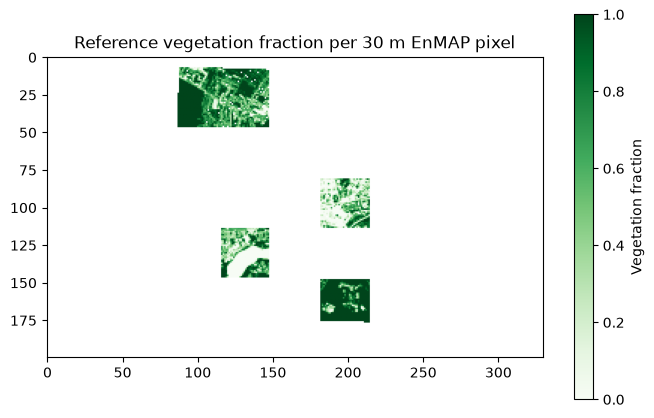

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(np.where(full, fractions["vegetation"], np.nan), cmap="Greens", vmin=0, vmax=1)
plt.colorbar(im, ax=ax, label="Vegetation fraction")
ax.set_title("Reference vegetation fraction per 30 m EnMAP pixel")
plt.show()

## 3. Spectral library

Pure pixels (100 % of one class, soil at least 90 % because it is rare) form the library.
The aerial reference is from April 2019, the EnMAP scene from July 2022, so some "soil" and
"impervious" pixels were green in July. They are removed with NDVI rules
(impervious and soil NDVI ≤ 0.3, vegetation NDVI ≥ 0.5; NDVI is not meaningful for water).

In [8]:
# All pixels as a table: one row per pixel, one column per used band
X_all = refl[use].reshape(use.sum(), -1).T
full_flat = full.ravel()

THRESHOLDS = {"impervious": 1.0, "vegetation": 1.0, "soil": 0.9, "water": 1.0}

lib_X, lib_class, lib_idx = [], [], []
for c, th in THRESHOLDS.items():
    idx = np.where(full_flat & (fractions[c].ravel() >= th))[0]
    idx = idx[~np.isnan(X_all[idx]).any(axis=1)]
    lib_X.append(X_all[idx])
    lib_class += [c] * len(idx)
    lib_idx.append(idx)

lib_X = np.vstack(lib_X)
lib_class = np.array(lib_class)
lib_idx = np.concatenate(lib_idx)

# NDVI filter
red = np.argmin(np.abs(wl_use - 665))
nir = np.argmin(np.abs(wl_use - 865))
with np.errstate(divide="ignore", invalid="ignore"):
    lib_ndvi = (lib_X[:, nir] - lib_X[:, red]) / (lib_X[:, nir] + lib_X[:, red])

keep = np.ones(len(lib_class), dtype=bool)
keep[np.isin(lib_class, ["impervious", "soil"]) & (lib_ndvi > 0.3)] = False
keep[(lib_class == "vegetation") & (lib_ndvi < 0.5)] = False

print("Before NDVI filter:", pd.Series(lib_class).value_counts().to_dict())
lib_X, lib_class, lib_idx = lib_X[keep], lib_class[keep], lib_idx[keep]
print("After NDVI filter: ", pd.Series(lib_class).value_counts().to_dict())

Before NDVI filter: {'vegetation': 1434, 'water': 239, 'impervious': 153, 'soil': 24}
After NDVI filter:  {'vegetation': 1415, 'water': 239, 'impervious': 143, 'soil': 14}


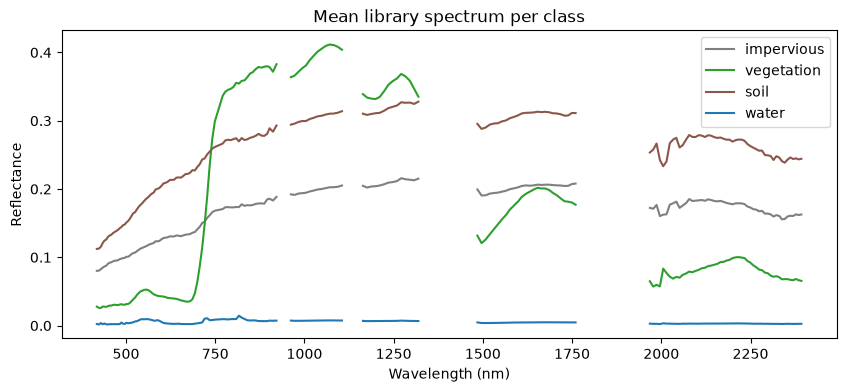

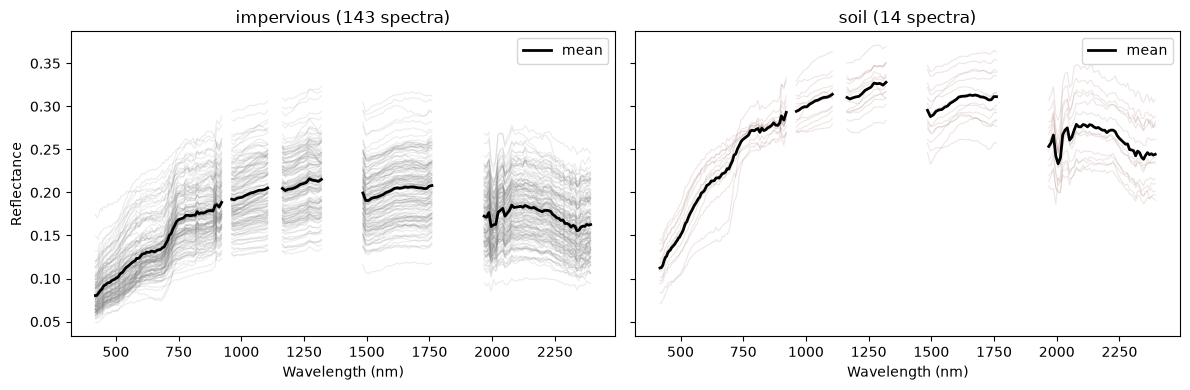

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for c in CLASSES:
    plot_with_gaps(ax, wl_use, lib_X[lib_class == c].mean(axis=0), color=COLORS[c], label=c)
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Reflectance")
ax.set_title("Mean library spectrum per class")
ax.legend()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, c in zip(axes, ["impervious", "soil"]):
    spectra = lib_X[lib_class == c]
    for s in spectra:
        plot_with_gaps(ax, wl_use, s, color=COLORS[c], alpha=0.15, linewidth=0.8)
    plot_with_gaps(ax, wl_use, spectra.mean(axis=0), color="black", linewidth=2, label="mean")
    ax.set_title(f"{c} ({len(spectra)} spectra)")
    ax.set_xlabel("Wavelength (nm)")
    ax.legend()
axes[0].set_ylabel("Reflectance")
plt.tight_layout()
plt.show()

## 4. Synthetic mixing and Random Forest regression

Mixed training spectra are created from the library: random classes (1 to 3 per mixture), random
fractions that sum to 1, linear mixing. One Random Forest predicts all four fractions.

The reference pixels not used in the library are split once into a **development set** (for
choosing settings) and a **final test set** (used only once at the end).

In [10]:
lib_by_class = {c: lib_X[lib_class == c] for c in CLASSES}


def synth_mix(n, rng, class_probs=None, complexity_probs={1: 0.2, 2: 0.5, 3: 0.3}):
    # Create n synthetic mixed spectra and their true fractions
    X = np.zeros((n, lib_X.shape[1]))
    Y = np.zeros((n, len(CLASSES)))
    ks = rng.choice(list(complexity_probs), size=n, p=list(complexity_probs.values()))
    for i, k in enumerate(ks):
        chosen = rng.choice(len(CLASSES), size=k, replace=False, p=class_probs)
        weights = rng.dirichlet(np.ones(k))
        for w, ci in zip(weights, chosen):
            spectra = lib_by_class[CLASSES[ci]]
            s = spectra[rng.integers(len(spectra))]
            X[i] += w * s
            Y[i, ci] += w
    return X, Y


# Reference pixels for testing: fully covered, not in the library, no missing values
test_mask = full_flat.copy()
test_mask[lib_idx] = False
test_mask &= ~np.isnan(X_all).any(axis=1)
test_idx = np.where(test_mask)[0]

dev_idx, final_idx = train_test_split(test_idx, test_size=0.5, random_state=SEED)
print("Development pixels:", len(dev_idx), "| final test pixels:", len(final_idx))


def evaluate(model, idx, W=None):
    # MAE, R2 and mean bias per class. If W is given, convert spectra to Sentinel-2 first
    X = X_all[idx]
    if W is not None:
        X = X @ W
    Y_true = np.column_stack([fractions[c].ravel()[idx] for c in CLASSES])
    Y_hat = model.predict(X)
    return pd.DataFrame({
        "MAE": [mean_absolute_error(Y_true[:, i], Y_hat[:, i]) for i in range(len(CLASSES))],
        "R2": [r2_score(Y_true[:, i], Y_hat[:, i]) for i in range(len(CLASSES))],
        "bias": Y_hat.mean(axis=0) - Y_true.mean(axis=0),
    }, index=CLASSES).round(3)

Development pixels: 1805 | final test pixels: 1806


### Class frequencies in the mixing

With equal class frequencies the model predicts far too much soil, taken mostly from impervious.
Three settings are compared on the development set.

In [11]:
VERSIONS = {
    "A equal":           [0.25, 0.25, 0.25, 0.25],
    "B less soil":       [0.30, 0.30, 0.10, 0.30],
    "C less soil+water": [0.375, 0.375, 0.10, 0.15],
}

for name, probs in VERSIONS.items():
    rng = np.random.default_rng(SEED)
    Xs, Ys = synth_mix(10000, rng, class_probs=probs)
    m = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED).fit(Xs, Ys)
    print(name)
    print(evaluate(m, dev_idx))
    print()

A equal
              MAE     R2   bias
impervious  0.167  0.439 -0.090
vegetation  0.148  0.583 -0.043
soil        0.122 -1.500  0.098
water       0.059  0.530  0.036

B less soil
              MAE     R2   bias
impervious  0.157  0.514 -0.052
vegetation  0.148  0.585 -0.047
soil        0.095 -0.967  0.067
water       0.057  0.547  0.032

C less soil+water
              MAE     R2   bias
impervious  0.153  0.544 -0.035
vegetation  0.146  0.594 -0.038
soil        0.085 -0.746  0.055
water       0.044  0.638  0.018



Version C is best for every class and is used from here on.

## 5. EnMAP vs simulated Sentinel-2

Sentinel-2 bands are simulated from the EnMAP bands with Gaussian band shapes (centre and FWHM of
Sentinel-2A). Both models are trained on **the same synthetic mixtures**, so the only difference is
the sensor.

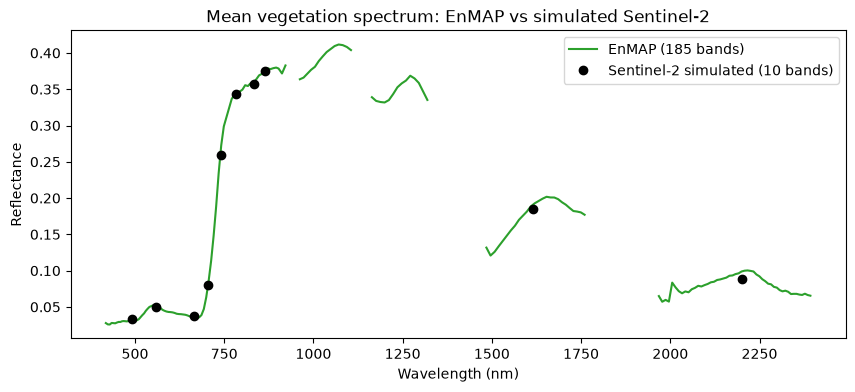

In [12]:
S2_BANDS = [
    ("B2", 492, 66), ("B3", 560, 36), ("B4", 665, 31),
    ("B5", 704, 15), ("B6", 740, 15), ("B7", 783, 20),
    ("B8", 833, 106), ("B8A", 865, 21),
    ("B11", 1614, 91), ("B12", 2202, 175),
]

W = np.zeros((len(wl_use), len(S2_BANDS)))
for j, (name, centre, width) in enumerate(S2_BANDS):
    sigma = width / 2.355
    w = np.exp(-0.5 * ((wl_use - centre) / sigma) ** 2)
    W[:, j] = w / w.sum()

s2_centres = np.array([b[1] for b in S2_BANDS])
veg_mean = lib_X[lib_class == "vegetation"].mean(axis=0)

fig, ax = plt.subplots(figsize=(10, 4))
plot_with_gaps(ax, wl_use, veg_mean, color="tab:green", label=f"EnMAP ({len(wl_use)} bands)")
ax.plot(s2_centres, veg_mean @ W, "o", color="black", label="Sentinel-2 simulated (10 bands)")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Reflectance")
ax.set_title("Mean vegetation spectrum: EnMAP vs simulated Sentinel-2")
ax.legend()
plt.show()

In [13]:
rng = np.random.default_rng(SEED)
Xs, Ys = synth_mix(10000, rng, class_probs=VERSIONS["C less soil+water"])

m_enmap = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED).fit(Xs, Ys)
m_s2 = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED).fit(Xs @ W, Ys)

res_enmap = evaluate(m_enmap, dev_idx)
res_s2 = evaluate(m_s2, dev_idx, W=W)
print("Development set, version C:")
print(pd.DataFrame({
    "MAE EnMAP": res_enmap["MAE"], "MAE S2": res_s2["MAE"],
    "R2 EnMAP": res_enmap["R2"], "R2 S2": res_s2["R2"],
}))

Development set, version C:
            MAE EnMAP  MAE S2  R2 EnMAP  R2 S2
impervious      0.153   0.157     0.544  0.522
vegetation      0.146   0.147     0.594  0.589
soil            0.085   0.084    -0.746 -0.780
water           0.044   0.041     0.638  0.641


## 6. Final test (used once)

All settings are fixed. The final test set is used here for the first and only time.

FINAL TEST SET:
            MAE EnMAP  MAE S2  R2 EnMAP  R2 S2  bias EnMAP
impervious      0.157   0.159     0.511  0.490      -0.036
vegetation      0.151   0.153     0.541  0.526      -0.046
soil            0.086   0.086    -1.076 -1.155       0.059
water           0.044   0.041     0.553  0.581       0.023


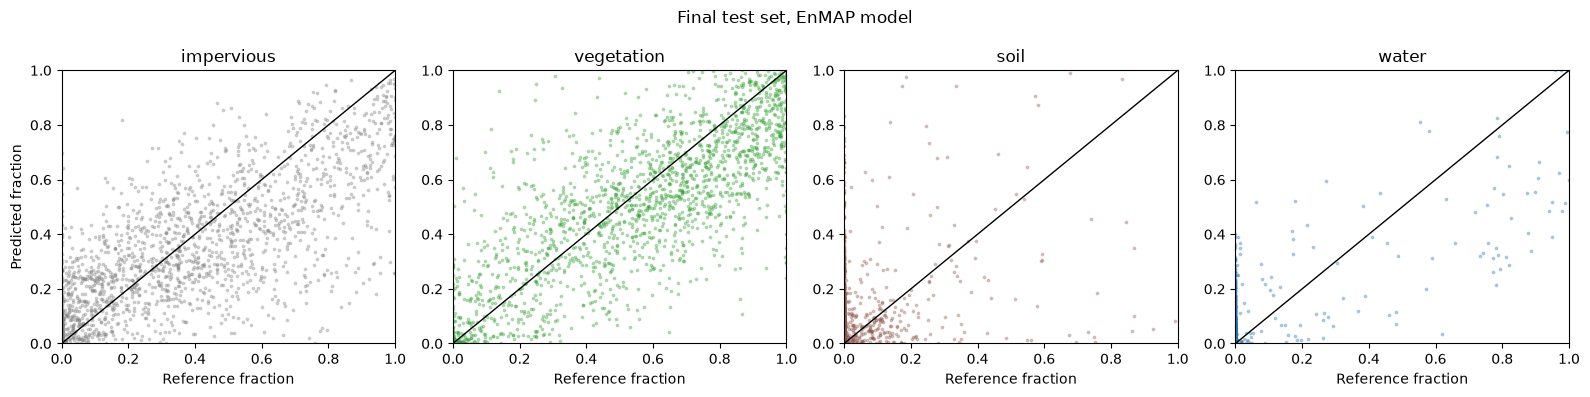

In [14]:
final_enmap = evaluate(m_enmap, final_idx)
final_s2 = evaluate(m_s2, final_idx, W=W)

final = pd.DataFrame({
    "MAE EnMAP": final_enmap["MAE"], "MAE S2": final_s2["MAE"],
    "R2 EnMAP": final_enmap["R2"], "R2 S2": final_s2["R2"],
    "bias EnMAP": final_enmap["bias"],
})
print("FINAL TEST SET:")
print(final)
final.to_csv(OUTPUTS / "final_test_results.csv")

# Predicted vs reference, EnMAP model
Y_true = np.column_stack([fractions[c].ravel()[final_idx] for c in CLASSES])
Y_hat = m_enmap.predict(X_all[final_idx])

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, (ax, c) in enumerate(zip(axes, CLASSES)):
    ax.scatter(Y_true[:, i], Y_hat[:, i], s=3, alpha=0.3, color=COLORS[c])
    ax.plot([0, 1], [0, 1], color="black", linewidth=1)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_title(c)
    ax.set_xlabel("Reference fraction")
axes[0].set_ylabel("Predicted fraction")
fig.suptitle("Final test set, EnMAP model")
plt.tight_layout()
fig.savefig(OUTPUTS / "final_test_scatter_enmap.png", dpi=150)
plt.show()

### Fraction maps for the whole image

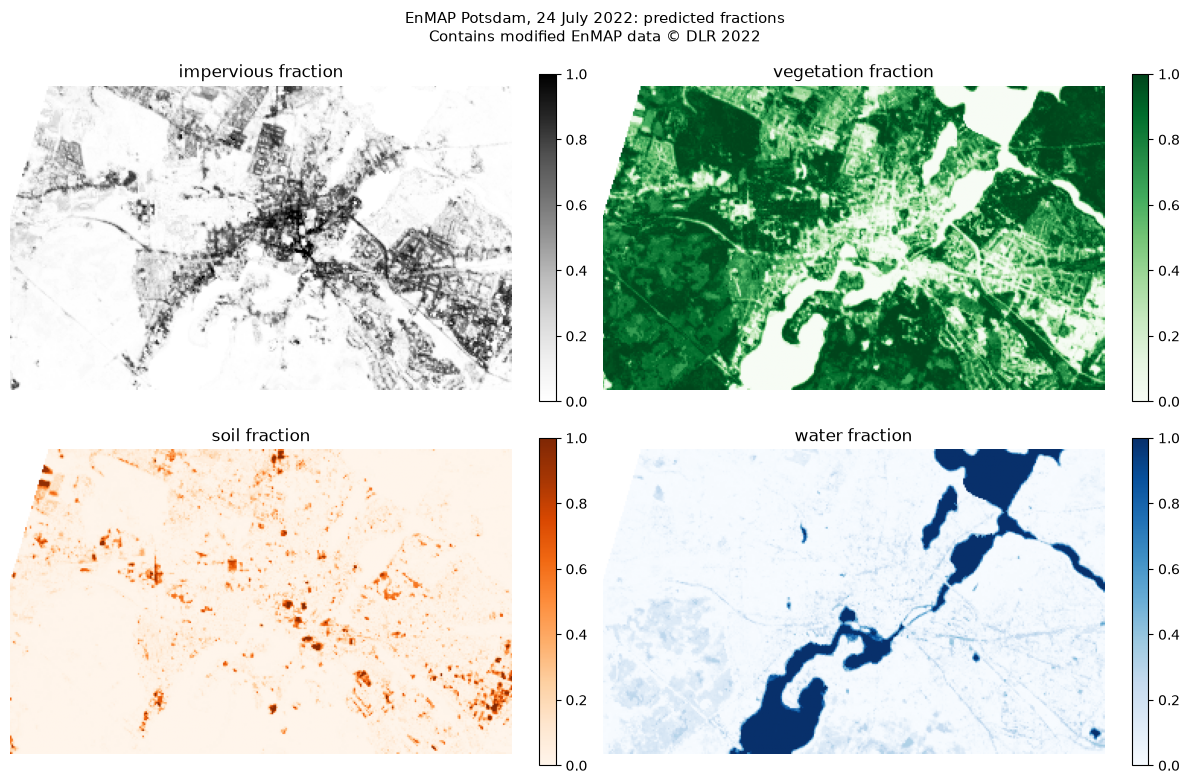

Saved fraction maps (PNG and GeoTIFF)


In [15]:
valid = ~np.isnan(X_all).any(axis=1)
pred_flat = np.full((X_all.shape[0], len(CLASSES)), np.nan, dtype="float32")
pred_flat[valid] = m_enmap.predict(X_all[valid])
pred_maps = pred_flat.reshape(n_rows, n_cols, len(CLASSES))

cmaps = {"impervious": "Greys", "vegetation": "Greens", "soil": "Oranges", "water": "Blues"}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, (ax, c) in enumerate(zip(axes.ravel(), CLASSES)):
    im = ax.imshow(pred_maps[:, :, i], cmap=cmaps[c], vmin=0, vmax=1)
    ax.set_title(f"{c} fraction")
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.03)
fig.suptitle("EnMAP Potsdam, 24 July 2022: predicted fractions\n"
             "Contains modified EnMAP data © DLR 2022", fontsize=11)
plt.tight_layout()
fig.savefig(OUTPUTS / "fraction_maps_enmap.png", dpi=150)
plt.show()

frac_da = xr.DataArray(
    np.moveaxis(pred_maps, 2, 0),
    dims=("band", "y", "x"),
    coords={"band": np.arange(1, len(CLASSES) + 1), "y": enmap.y, "x": enmap.x},
)
frac_da = frac_da.rio.write_crs(enmap.rio.crs).rio.write_nodata(np.nan)
frac_da.attrs["long_name"] = CLASSES
frac_da.rio.to_raster(OUTPUTS / "fractions_enmap_potsdam_2022.tif")
print("Saved fraction maps (PNG and GeoTIFF)")

## Results

| Class | MAE EnMAP | MAE Sentinel-2 (simulated) | R² EnMAP |
|---|---|---|---|
| Impervious | 0.157 | 0.159 | 0.51 |
| Vegetation | 0.151 | 0.153 | 0.54 |
| Soil | 0.086 | 0.086 | -1.08 |
| Water | 0.044 | 0.041 | 0.55 |

*Final test set, 1806 pixels.*

- Vegetation, impervious and water are mapped with a mean error of 4 to 16 percentage points.
- Soil is not predicted reliably (negative R²): it covers only about 3 % of the reference area and
  only 14 library spectra remain.
- **EnMAP and simulated Sentinel-2 perform almost equally for these four broad classes.** The errors
  are dominated by other factors (reference date, rare soil, shadows), not by spectral resolution.

## Limitations

- Reference from an aerial image of April 2019, EnMAP scene from July 2022.
- Soil is rare and underrepresented in the library.
- Dark surfaces (shadows, conifer forest) are partly predicted as water.
- EnMAP processor version 01.03.02; according to Brell et al. (2026), products from version 01.05.02
  onwards are more consistent.
- L2A processed in land mode: water reflectance close to 0, not suitable for water analyses.
- Sentinel-2 is simulated from EnMAP (Gaussian band shapes, 30 m, EnMAP noise level), so it is an
  idealised Sentinel-2.

## Next step

Test where hyperspectral data makes a difference: finer classes such as tree vs low vegetation.

## References

- Okujeni, A., van der Linden, S., Tits, L., Somers, B., Hostert, P. (2013): Support vector regression
  and synthetically mixed training data for quantifying urban land cover. *Remote Sensing of
  Environment* 137, 184-197.
- Brell, M. et al. (2026): Assessment of EnMAP data quality through global product validation
  activities. *Remote Sensing of Environment* 342, 115459.
- Jakimow, B. et al. (2023): EnMAP-Box: Imaging spectroscopy in QGIS. *SoftwareX* 23, 101507.